In [1]:
# 60043
import os
import warnings

import altair as alt
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import seaborn as sns
import umap
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multicomp import pairwise_tukeyhsd

warnings.filterwarnings("ignore")
pio.renderers.default = "plotly_mimetype+notebook_connected"

# EDA - ceny domów w stanie Waszyngton

Zbiór: [shree1992/housedata](https://www.kaggle.com/datasets/shree1992/housedata) - 4600 sprzedanych domów z okolic Seattle (maj-lipiec 2014).

In [2]:
path = kagglehub.dataset_download("shree1992/housedata")
print("Dane w:", path)

Dane w: /home/kfirlej/.cache/kagglehub/datasets/shree1992/housedata/versions/2


## 1. Wczytanie i przygotowanie danych

In [3]:
df = pd.read_csv(os.path.join(path, "data.csv"))
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           4600 non-null   str    
 1   price          4600 non-null   float64
 2   bedrooms       4600 non-null   float64
 3   bathrooms      4600 non-null   float64
 4   sqft_living    4600 non-null   int64  
 5   sqft_lot       4600 non-null   int64  
 6   floors         4600 non-null   float64
 7   waterfront     4600 non-null   int64  
 8   view           4600 non-null   int64  
 9   condition      4600 non-null   int64  
 10  sqft_above     4600 non-null   int64  
 11  sqft_basement  4600 non-null   int64  
 12  yr_built       4600 non-null   int64  
 13  yr_renovated   4600 non-null   int64  
 14  street         4600 non-null   str    
 15  city           4600 non-null   str    
 16  statezip       4600 non-null   str    
 17  country        4600 non-null   str    
dtypes: float64(4), int6

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
price,4600.0,551962.988473,563834.702547,0.0,322875.00,460943.461539,654962.50,26590000.0
bedrooms,4600.0,3.400870,0.908848,0.0,3.00,3.000000,4.00,9.0
bathrooms,4600.0,2.160815,0.783781,0.0,1.75,2.250000,2.50,8.0
sqft_living,4600.0,2139.346957,963.206916,370.0,1460.00,1980.000000,2620.00,13540.0
sqft_lot,4600.0,14852.516087,35884.436145,638.0,5000.75,7683.000000,11001.25,1074218.0
floors,4600.0,1.512065,0.538288,1.0,1.00,1.500000,2.00,3.5
waterfront,4600.0,0.007174,0.084404,0.0,0.00,0.000000,0.00,1.0
view,4600.0,0.240652,0.778405,0.0,0.00,0.000000,0.00,4.0
condition,4600.0,3.451739,0.677230,1.0,3.00,3.000000,4.00,5.0
sqft_above,4600.0,1827.265435,862.168977,370.0,1190.00,1590.000000,2300.00,9410.0


In [5]:
print("braki:", df.isna().sum().sum())
print("duplikaty:", df.duplicated().sum())
print("cena 0:", (df["price"] == 0).sum())
print("0 sypialni:", (df["bedrooms"] == 0).sum())
print("0 łazienek:", (df["bathrooms"] == 0).sum())

braki: 0
duplikaty: 0
cena 0: 49
0 sypialni: 2
0 łazienek: 2


In [6]:
df = df.dropna().copy()
df = df[(df["price"] > 0) & (df["bedrooms"] > 0) & (df["bathrooms"] > 0)].copy()
print(df["country"].value_counts())
df = df.drop(columns=["country"])
df["m2"] = (df["sqft_living"] * 0.092903).round(1)
print(df.shape)

country
USA    4549
Name: count, dtype: int64
(4549, 18)


**Obserwacje:** brak braków i duplikatów, ale 49 domów miało cenę 0, a 2 domy 0 sypialni i łazienek, więc je usunąłem. Kolumna `country` ma tylko USA, więc też poszła. Zostało 4549 domów.

## 2. Rozkład cen

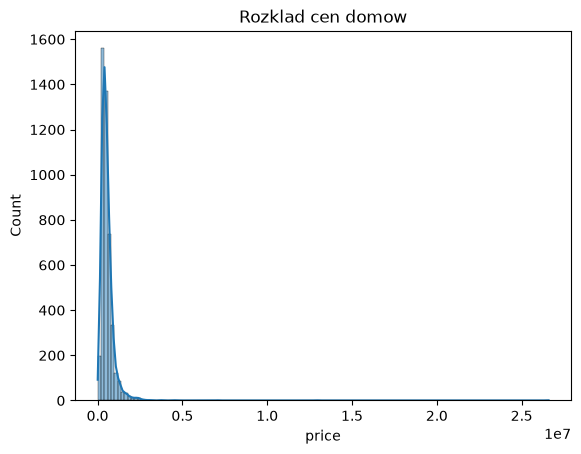

In [7]:
sns.histplot(df["price"], kde=True)
plt.title("Rozklad cen domow")
plt.show()

In [8]:
print("średnia:", round(df["price"].mean()))
print("mediana:", round(df["price"].median()))
print("skośność:", round(df["price"].skew(), 2))

średnia: 557626
mediana: 465000
skośność: 25.04


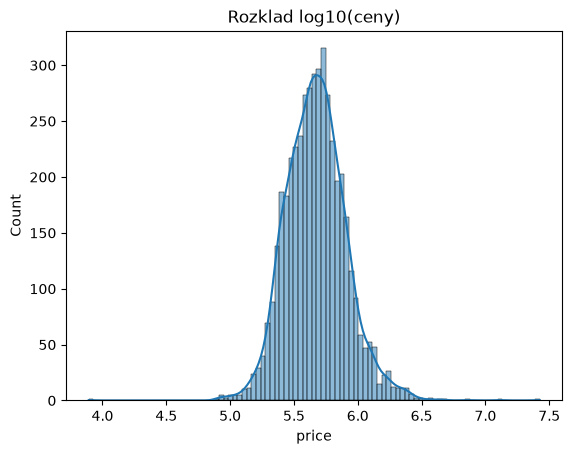

In [9]:
sns.histplot(np.log10(df["price"]), kde=True)
plt.title("Rozklad log10(ceny)")
plt.show()

**Obserwacje:** rozkład cen jest mocno skośny w prawo, średnia (558 tys.) jest większa od mediany (465 tys.). Po logarytmie wygląda dużo normalniej i widać kilka cen daleko od reszty.

## 3. Wartości odstające

### 3.1. Isolation Forest

In [10]:
iso = IsolationForest(contamination=0.05, random_state=42)
df["outliers"] = iso.fit_predict(df[["price", "m2"]])
print(df["outliers"].value_counts())
print("tanie (< 150 tys.) wśród odstających:", ((df["outliers"] == -1) & (df["price"] < 150_000)).sum())

outliers
 1    4321
-1     228
Name: count, dtype: int64
tanie (< 150 tys.) wśród odstających: 16


In [11]:
df[df["outliers"] == -1].sort_values("price", ascending=False)[["price", "m2", "bedrooms", "bathrooms", "city"]].head(15)

,price,m2,bedrooms,bathrooms,city
4350,26590000.0,109.6,3.0,2.00,Kent
4346,12899000.0,203.5,3.0,2.50,Seattle
2286,7062500.0,932.7,5.0,4.50,Bellevue
2654,4668000.0,895.6,5.0,6.75,Mercer Island
2761,4489000.0,597.4,4.0,3.00,Bellevue
3729,3800000.0,655.0,5.0,5.50,Clyde Hill
1637,3710000.0,515.6,4.0,3.50,Medina
252,3200000.0,576.9,7.0,4.50,Seattle
1567,3100000.0,648.5,6.0,4.25,Mercer Island
2772,3000000.0,450.6,4.0,4.25,Kirkland


In [12]:
print(df.groupby("outliers")[["price", "m2"]].median())

              price     m2
outliers                  
-1        1508000.0  398.1
 1         453000.0  179.3


**Obserwacje:** Isolation Forest oznaczył 228 domów (5%). Większość to po prostu duże i drogie domy. Podejrzane są dwa: dom w Kent za 26,6 mln przy 110 m² i dom w Seattle za 12,9 mln przy 203 m², tu cena nie pasuje do metrażu, pewnie błąd w danych.

### 3.2. Wizualizacja

In [13]:
df["status"] = df["outliers"].map({1: "normalna", -1: "odstajaca"})
fig = px.scatter(df, x="m2", y="price", color="status", title="Wartosci odstajace w danych")
fig.show()

**Obserwacje:** odstające punkty są na brzegach chmury, przy dużym metrażu albo wysokiej cenie. Dwa punkty wiszą wysoko przy małym metrażu, to te podejrzane domy.

## 4. PCA

In [14]:
cechy = ["m2", "bedrooms", "bathrooms", "floors", "sqft_lot"]
X = StandardScaler().fit_transform(df[cechy])

pca = PCA(n_components=2)
pcs = pca.fit_transform(X)
df["PC1"], df["PC2"] = pcs[:, 0], pcs[:, 1]
print(pca.explained_variance_ratio_)
print(pca.explained_variance_ratio_.sum())

[0.50899606 0.2024582 ]
0.7114542601362737


In [15]:
pd.DataFrame(pca.components_, columns=cechy, index=["PC1", "PC2"]).round(2)

,m2,bedrooms,bathrooms,floors,sqft_lot
PC1,0.56,0.47,0.57,0.36,0.14
PC2,0.10,0.03,-0.10,-0.39,0.91


In [16]:
fig = px.scatter(df, x="PC1", y="PC2", color="price", range_color=[0, df["price"].quantile(0.95)],
                 title="Wizualizacja glownych skladowych")
fig.show()

**Obserwacje:** dwie składowe wyjaśniają 71% zmienności. PC1 to głównie wielkość domu (metraż, sypialnie, łazienki), PC2 to działka. Droższe domy są po prawej, czyli cena rośnie z PC1.

## 5. t-SNE

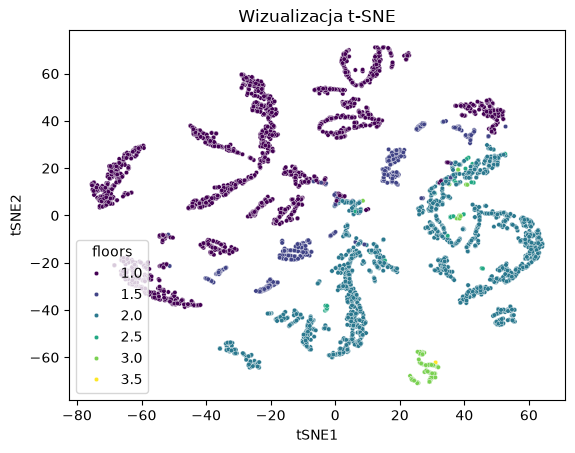

In [17]:
tsne = TSNE(n_components=2, random_state=42, init="pca")
ts = tsne.fit_transform(X)
df["tSNE1"], df["tSNE2"] = ts[:, 0], ts[:, 1]

sns.scatterplot(data=df, x="tSNE1", y="tSNE2", hue="floors", palette="viridis", s=10)
plt.title("Wizualizacja t-SNE")
plt.show()

**Obserwacje:** t-SNE dzieli dane na dużo małych skupisk, głównie według liczby pięter.

## 6. UMAP

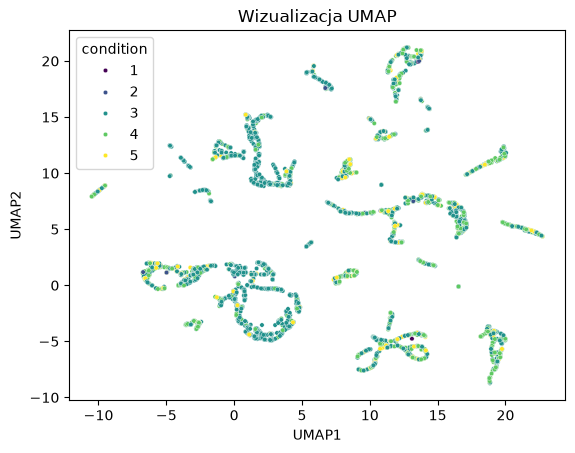

In [18]:
reducer = umap.UMAP(n_neighbors=10, min_dist=0.1, random_state=42)
um = reducer.fit_transform(X)
df["UMAP1"], df["UMAP2"] = um[:, 0], um[:, 1]

sns.scatterplot(data=df, x="UMAP1", y="UMAP2", hue="condition", palette="viridis", s=10)
plt.title("Wizualizacja UMAP")
plt.show()

**Obserwacje:** UMAP daje podobne skupiska jak t-SNE. Stan techniczny jest wymieszany w każdej grupie, więc nie zależy od wielkości domu.

## 7. Interaktywny wykres w Altair

In [19]:
chart = alt.Chart(df).mark_circle(size=60).encode(
    x="m2",
    y="price",
    color="bedrooms:N",
    tooltip=["m2", "price", "bedrooms", "bathrooms", "city"],
).interactive()

chart

alt.Chart(...)

**Obserwacje:** wykres pozwala najechać na punkt i zobaczyć szczegóły. Domy z większą liczbą sypialni są po prawej, cena rośnie z metrażem, ale rozrzut jest duży.

## 8. Macierz korelacji

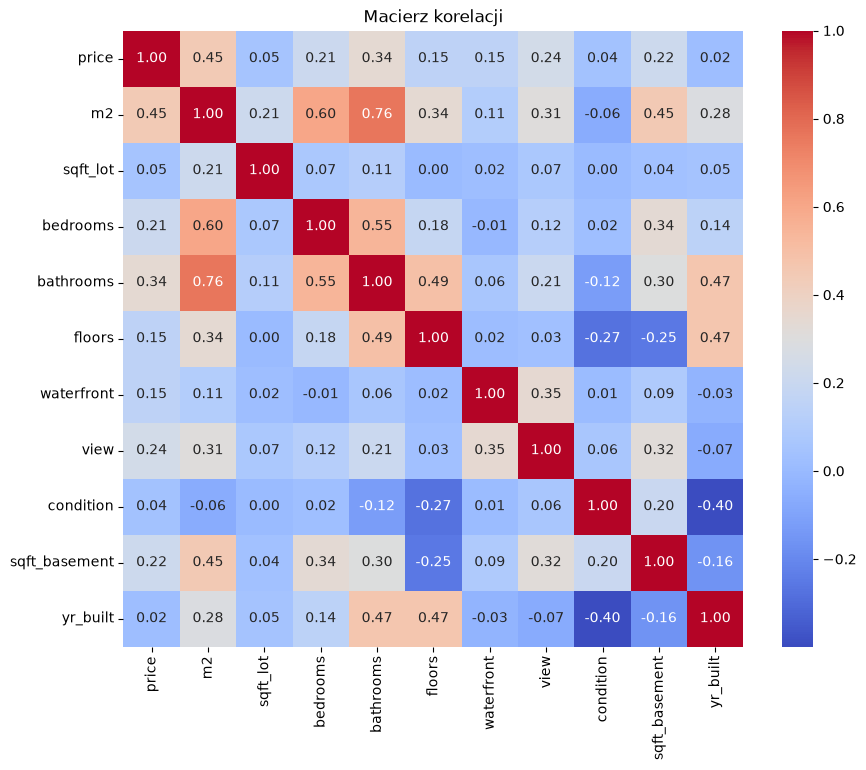

In [20]:
kolumny = ["price", "m2", "sqft_lot", "bedrooms", "bathrooms", "floors", "waterfront", "view", "condition",
           "sqft_basement", "yr_built"]
corr = df[kolumny].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Macierz korelacji")
plt.show()

In [21]:
print(corr["price"].drop("price").sort_values(ascending=False).round(2))

m2               0.45
bathrooms        0.34
view             0.24
sqft_basement    0.22
bedrooms         0.21
floors           0.15
waterfront       0.15
sqft_lot         0.05
condition        0.04
yr_built         0.02
Name: price, dtype: float64


In [22]:
bez_bledow = df[df["price"] < 10_000_000]
print("Pearson, wszystkie domy:", round(df["price"].corr(df["m2"]), 2))
print("Pearson, bez 2 rekordów > 10 mln:", round(bez_bledow["price"].corr(bez_bledow["m2"]), 2))
print("Spearman, wszystkie domy:", round(df["price"].corr(df["m2"], method="spearman"), 2))

Pearson, wszystkie domy: 0.45
Pearson, bez 2 rekordów > 10 mln: 0.7
Spearman, wszystkie domy: 0.66


**Obserwacje:** cena najbardziej koreluje z metrażem (0,45) i łazienkami (0,34). Metraż mocno wiąże się z łazienkami i sypialniami. Po usunięciu dwóch podejrzanych domów korelacja ceny z metrażem rośnie do 0,70.

## 9. Test ANOVA

In [23]:
print(df["bedrooms"].value_counts().sort_index())

bedrooms
1.0      37
2.0     561
3.0    2025
4.0    1512
5.0     338
6.0      59
7.0      14
8.0       2
9.0       1
Name: count, dtype: int64


In [24]:
model = ols("price ~ C(bedrooms)", data=df).fit()
print(anova_lm(model))

                 df        sum_sq       mean_sq          F        PR(>F)
C(bedrooms)     8.0  6.741676e+13  8.427095e+12  27.749518  1.754662e-42
Residual     4540.0  1.378727e+15  3.036844e+11        NaN           NaN


In [25]:
print(df.groupby("bedrooms")["price"].agg(["count", "mean", "median"]).round())

          count       mean     median
bedrooms                             
1.0          37   281484.0   275000.0
2.0         561   395112.0   370000.0
3.0        2025   490302.0   425000.0
4.0        1512   643100.0   575000.0
5.0         338   804366.0   599000.0
6.0          59   845070.0   670000.0
7.0          14  1049429.0   711500.0
8.0           2  1155000.0  1155000.0
9.0           1   599999.0   599999.0


In [26]:
grupy = df[df["bedrooms"].between(1, 6)]
print(pairwise_tukeyhsd(grupy["price"], grupy["bedrooms"]))

      Multiple Comparison of Means - Tukey HSD, FWER=0.05       
group1 group2   meandiff  p-adj     lower        upper    reject
----------------------------------------------------------------
   1.0    2.0 113628.5259 0.8284 -152403.3639 379660.4157  False
   1.0    3.0  208818.271 0.1984   -51195.503 468832.0449  False
   1.0    4.0 361616.5773 0.0011  100812.5152 622420.6395   True
   1.0    5.0 522882.0565    0.0  251474.5707 794289.5422   True
   1.0    6.0 563586.2727    0.0  234905.6138 892266.9316   True
   2.0    3.0  95189.7451 0.0039   20409.7011  169969.789   True
   2.0    4.0 247988.0514    0.0  170504.8199 325471.2829   True
   2.0    5.0 409253.5305    0.0  301332.6537 517174.4074   True
   2.0    6.0 449957.7468    0.0   235444.652 664470.8416   True
   3.0    4.0 152798.3064    0.0    99526.856 206069.7567   True
   3.0    5.0 314063.7855    0.0  221970.8329 406156.7381   True
   3.0    6.0 354768.0017    0.0  147765.4315  561770.572   True
   4.0    5.0 161265.4791

**Obserwacje:** p jest dużo mniejsze od 0,05, więc średnia cena różni się zależnie od liczby sypialni. Test Tukeya pokazuje, że większość par się różni, ale np. 1-2 albo 5-6 sypialni już nie.